In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
# download the data 
data = pd.read_csv('data/raw/train.csv')

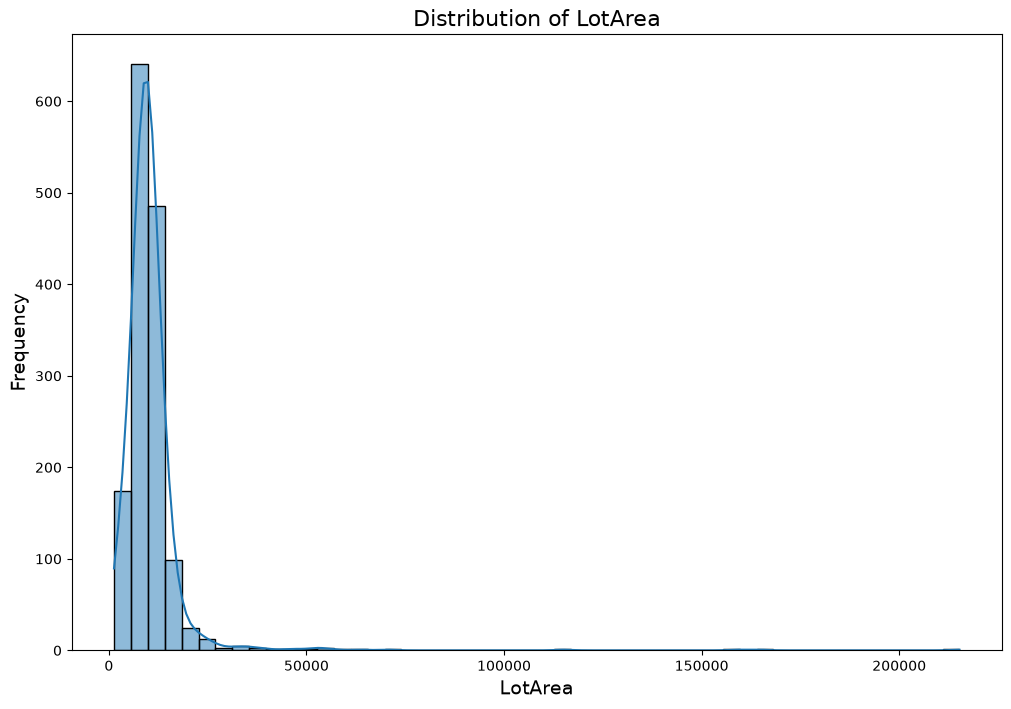

In [3]:
plt.figure(figsize=(12, 8))
plt.title('Distribution of LotArea', fontsize=16)
sns.histplot(data['LotArea'], bins=50, kde=True)
plt.xlabel('LotArea', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.show()

In [4]:
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

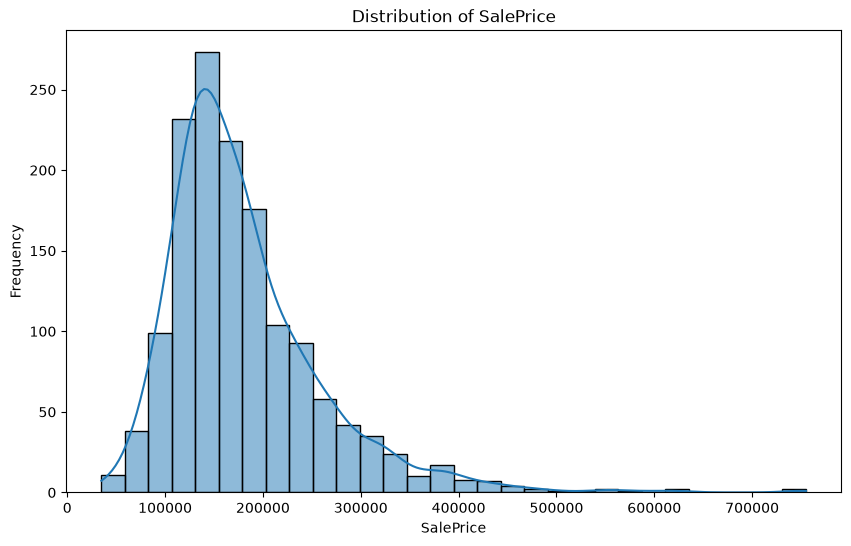

In [6]:
# visualiser SalePrice
plt.figure(figsize=(10, 6))
plt.title('Distribution of SalePrice')
sns.histplot(data['SalePrice'], kde=True, bins=30)
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.show()

In [7]:
data[['SalePrice']].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


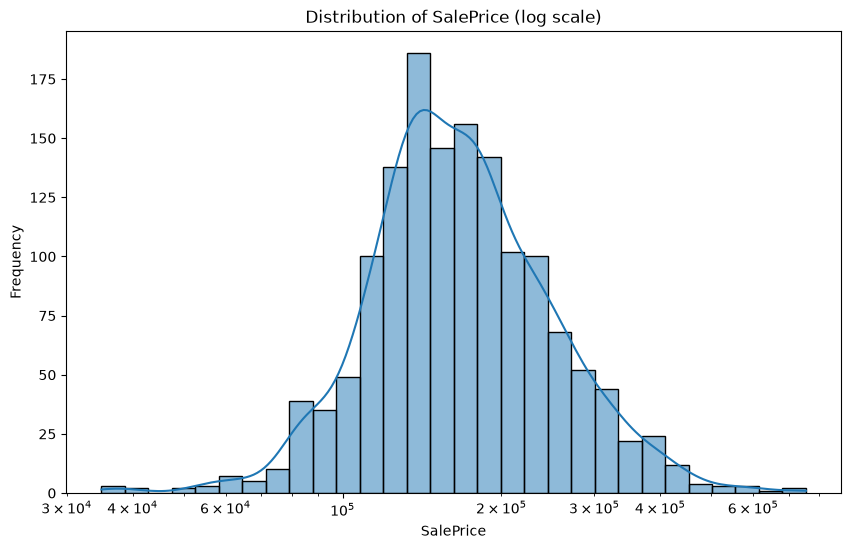

In [8]:
plt.figure(figsize=(10, 6))
plt.title('Distribution of SalePrice (log scale)')
sns.histplot(data['SalePrice'], kde=True, bins=30, log_scale=True)
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.show()

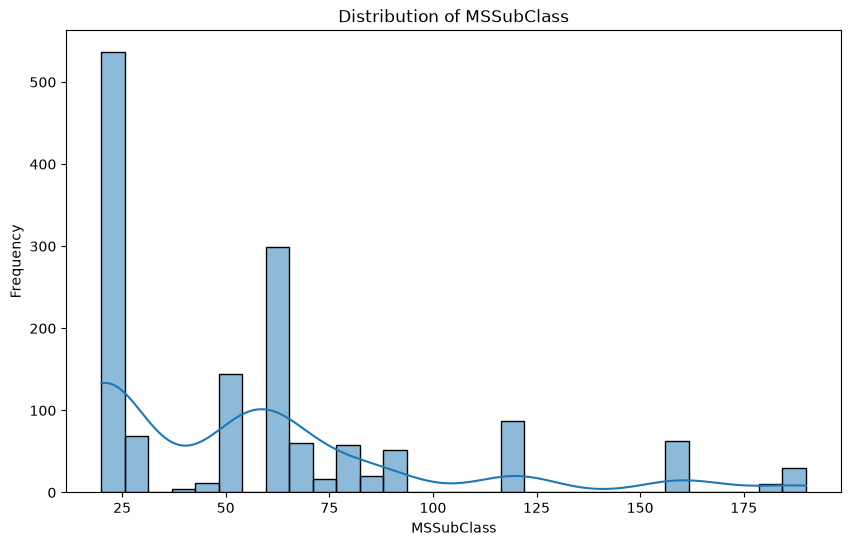

In [9]:
plt.figure(figsize=(10, 6))
plt.title('Distribution of MSSubClass')
sns.histplot(data['MSSubClass'], kde=True, bins=30)
plt.xlabel('MSSubClass')
plt.ylabel('Frequency')
plt.show()

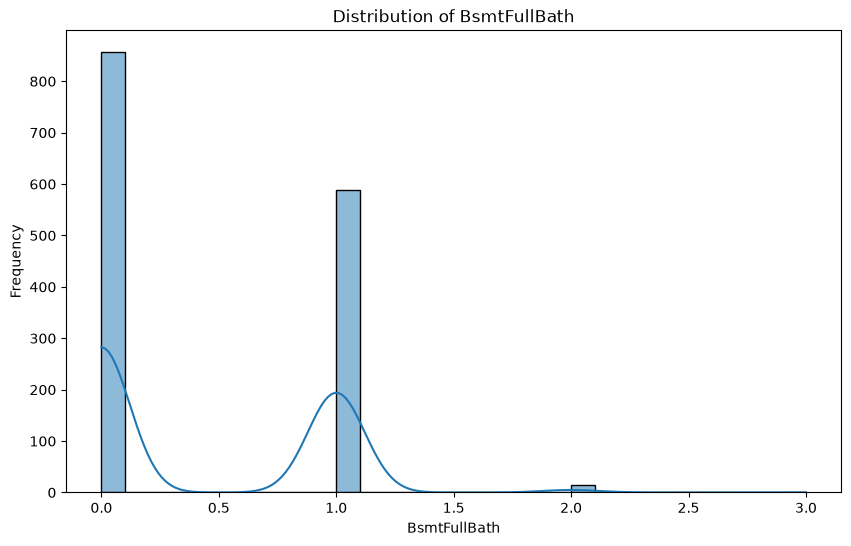

In [10]:
plt.figure(figsize=(10, 6))
plt.title('Distribution of BsmtFullBath')
sns.histplot(data['BsmtFullBath'], kde=True, bins=30)
plt.xlabel('BsmtFullBath')
plt.ylabel('Frequency')
plt.show()

In [11]:
data['GarageYrBlt'].isna().sum()

np.int64(81)

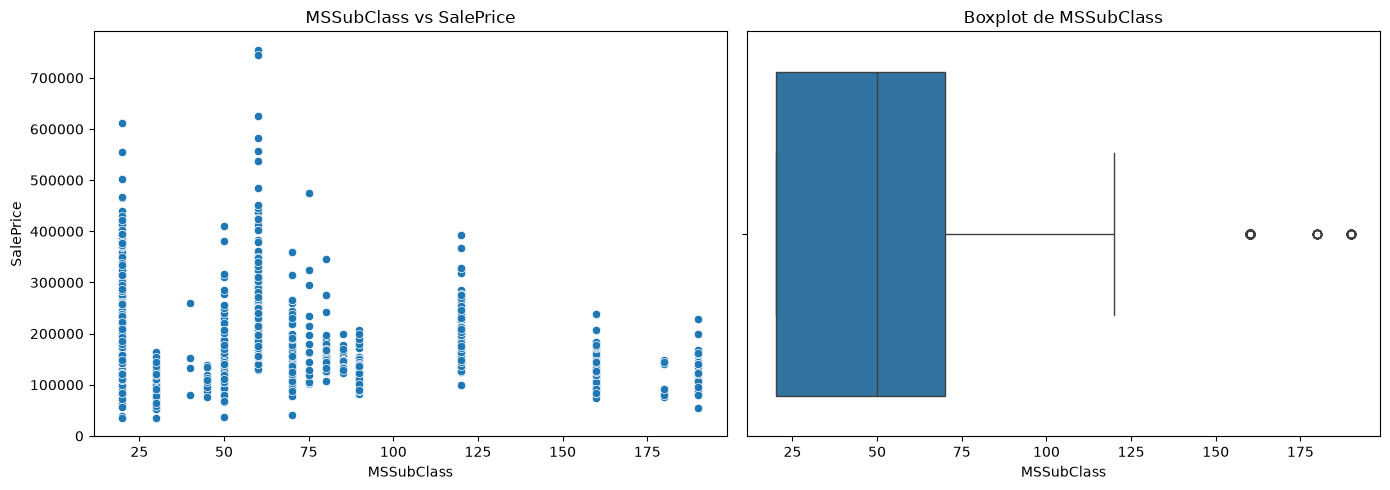

In [14]:
# EDA POUR data_train

for i in data.columns:

    # Garder uniquement les variables numériques et exclure Id + SalePrice
    if (data[i].dtype in ['int64', 'float64']) and i not in ['Id', 'SalePrice']:

        # Garder uniquement les lignes où i et SalePrice ne sont pas NaN
        data = data[[i, 'SalePrice']].dropna()

        # Créer une figure avec 2 graphiques
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # A. Scatter plot : variable vs SalePrice
        sns.scatterplot(
            data=data,
            x=i,
            y='SalePrice',
            ax=axes[0]
        )

        axes[0].set_title(f'{i} vs SalePrice')
        axes[0].set_xlabel(i)
        axes[0].set_ylabel('SalePrice')

        # B. Boxplot : détection des outliers
        sns.boxplot(
            x=data[i],
            ax=axes[1]
        )

        axes[1].set_title(f'Boxplot de {i}')
        axes[1].set_xlabel(i)

        # Ajuster l'espace entre les graphiques
        plt.tight_layout()
        plt.show()



In [18]:
data_train = data.copy()
for i in data_train.columns:
# Garder uniquement les variables numériques et exclure Id + SalePrice
    if (data_train[i].dtype not in ['int64', 'float64']) and i not in ['Id', 'SalePrice']:

        # Garder uniquement les lignes où i et SalePrice ne sont pas NaN
        data = data_train[[i, 'SalePrice']].dropna()

        # Créer une figure avec 2 graphiques
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # A. Scatter plot : variable vs SalePrice
        sns.scatterplot(
            data=data,
            x=i,
            y='SalePrice',
            ax=axes[0]
        )

        axes[0].set_title(f'{i} vs SalePrice')
        axes[0].set_xlabel(i)
        axes[0].set_ylabel('SalePrice')

                # B. Boxplot : détection des outliers
        sns.boxplot(x= i, y='SalePrice', data=data_train)

        axes[1].set_title(f'Boxplot de {i}')
        axes[1].set_xlabel(i)

        # Ajuster l'espace entre les graphiques
        plt.tight_layout()
        plt.show()

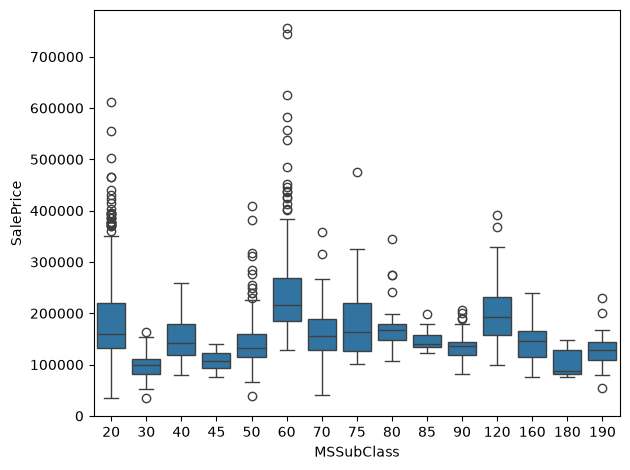

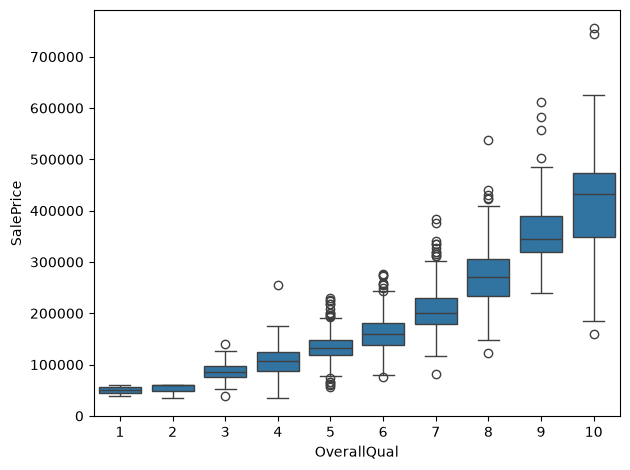

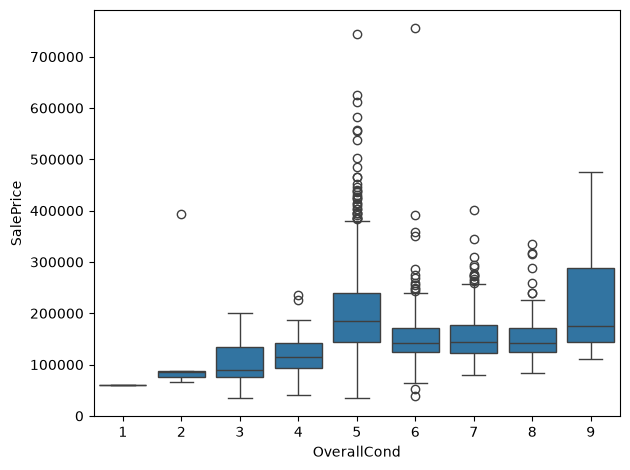

In [ ]:
# B. Boxplot : détection des outliers
sns.boxplot(x= data_train["MSSubClass"], y='SalePrice', data=data_train)
axes[1].set_title(f'Boxplot de {i}')
axes[1].set_xlabel(i)
# .Ajuster l'espace entre les graphiques
plt.tight_layout()
plt.show()

# B. Boxplot : détection des outliers
sns.boxplot(x= data_train["OverallQual"], y='SalePrice', data=data_train)
axes[1].set_title(f'Boxplot de {i}')
axes[1].set_xlabel(i)
# .Ajuster l'espace entre les graphiques
plt.tight_layout()
plt.show()

# B. Boxplot : détection des outliers
sns.boxplot(x= data_train["OverallCond"], y='SalePrice', data=data_train)
axes[1].set_title(f'Boxplot de {i}')
axes[1].set_xlabel(i)
# .Ajuster l'espace entre les graphiques
plt.tight_layout()
plt.show()